# Module 7 — Pré-entraînement et Hugging Face

> **Objectif** : comprendre le paradigme qui a révolutionné le NLP en 2018 : **pré-entraîner** un Transformer sur d'énormes quantités de texte non annoté, puis l'**affiner** (*fine-tuning*) sur une tâche précise avec peu de données. On détaille les objectifs de pré-entraînement (CLM de GPT, MLM de BERT, et leurs variantes), puis on prend en main l'écosystème **Hugging Face** pour la classification de textes, l'**étiquetage de tokens** (avec le délicat alignement étiquettes / sous-mots) et la génération.

| | |
|---|---|
| **Durée estimée** | 3 h |
| **Prérequis** | Modules 0 à 6 |
| **Librairies** | `numpy`, `matplotlib` ; `torch`, `transformers`, `datasets`, `accelerate` (sections 4 à 9) |

**Plan**

1. Le paradigme pré-entraînement → affinage
2. Les objectifs de pré-entraînement : CLM, MLM et variantes
3. Lois d'échelle : combien de paramètres, combien de données ?
4. L'écosystème Hugging Face en 10 minutes
5. Décoder : greedy, beam search, échantillonnage
6. Affiner pour la classification de séquences
7. Affiner pour l'étiquetage de tokens (NER, délimitation de segments)
8. Extraire des embeddings de phrases
9. Des modèles de base aux assistants : instruction tuning et alignement
10. Récapitulatif et exercices

> ⚙️ `pip install "transformers>=4.46" datasets accelerate`. Les modèles sont téléchargés depuis le Hub Hugging Face au premier appel (quelques centaines de Mo). Un GPU (Colab) est fortement conseillé pour les sections 6 et 7.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
rng = np.random.default_rng(0)

## 1. Le paradigme pré-entraînement → affinage

### 💡 Intuition

Avant 2018, chaque tâche (sentiment, NER, traduction) s'entraînait **de zéro** sur son propre jeu annoté, souvent quelques milliers d'exemples. Le modèle devait tout apprendre de la langue (syntaxe, sens des mots, connaissances du monde) à partir de ces quelques exemples.

L'idée du pré-entraînement : la langue est la même pour toutes les tâches. On entraîne d'abord un grand modèle sur une tâche **auto-supervisée** (prédire des mots, comme word2vec au module 3 et les modèles de langue au module 4), sur des milliards de mots **non annotés**, qui sont gratuits. Le modèle y acquiert une représentation générale de la langue. Puis on **affine** ce modèle sur la tâche cible avec un petit jeu annoté : il n'a plus qu'à apprendre la tâche, pas la langue.

C'est l'**apprentissage par transfert**, déjà standard en vision (ImageNet) et généralisé au NLP par ULMFiT, ELMo, GPT et **BERT** (2018).

| Étape | Données | Objectif | Coût |
|---|---|---|---|
| Pré-entraînement | $10^9$–$10^{13}$ tokens bruts | auto-supervisé (CLM / MLM) | jours–mois sur des centaines de GPU |
| *(optionnel)* Pré-entraînement continu sur le domaine | corpus du domaine (biomédical, juridique, protéines…) | le même objectif | heures–jours |
| Affinage (*fine-tuning*) | $10^2$–$10^5$ exemples annotés | supervisé (classification, étiquetage…) | minutes–heures sur 1 GPU |

L'étape intermédiaire, **le pré-entraînement adaptatif au domaine (DAPT) ou à la tâche (TAPT)**, sera détaillée au module 8.

## 2. Les objectifs de pré-entraînement

### 2.1 CLM : modèle de langue causal (GPT)

Exactement le module 4 et le mini-GPT du module 6 : prédire chaque token à partir des précédents, avec un masque causal.
$$
\mathcal L_{\text{CLM}} = -\sum_{t=1}^{T}\log p_\theta(x_t\mid x_{<t})
$$
- ✅ chaque token fournit un signal d'apprentissage (100 % des positions) ;
- ✅ le modèle sait **générer** ;
- ❌ chaque représentation ne voit que le contexte **gauche** : sous-optimal pour comprendre un mot dont le sens dépend de la suite.

### 2.2 MLM : modèle de langue masqué (BERT)

On masque une partie des tokens et on demande au modèle (bidirectionnel, sans masque causal) de les reconstruire à partir du contexte **des deux côtés** :
$$
\mathcal L_{\text{MLM}} = -\sum_{t\in\mathcal M}\log p_\theta(x_t\mid \tilde x)
$$
où $\mathcal M$ est l'ensemble des positions sélectionnées (15 % des tokens) et $\tilde x$ la séquence corrompue. **La perte n'est calculée que sur les positions sélectionnées.**

**La règle 80 / 10 / 10.** Parmi les 15 % de positions sélectionnées :
- 80 % sont remplacées par `[MASK]` ;
- 10 % par un token **aléatoire** ;
- 10 % sont **laissées intactes**.

Pourquoi ? Le token `[MASK]` n'apparaît **jamais** lors de l'affinage ni de l'inférence. Si on masquait toujours, le modèle apprendrait à ne produire de bonnes représentations qu'aux positions `[MASK]`. Avec les 10 % aléatoires et les 10 % intacts, il ne sait jamais quelle position est « piégée » : il doit maintenir une représentation contextuelle juste **pour chaque token**.

In [2]:
def mlm_mask(ids, vocab_size, mask_id, special_ids, p=0.15, rng=rng):
    """Returns (corrupted inputs, labels) following BERT's 80/10/10 rule. labels = -100 where no loss."""
    ids = np.array(ids)
    labels = np.full_like(ids, -100)
    candidates = ~np.isin(ids, special_ids)                       # never mask [CLS], [SEP], [PAD]
    selected = candidates & (rng.random(ids.shape) < p)
    labels[selected] = ids[selected]                              # loss only on selected positions
    corrupted = ids.copy()
    u = rng.random(ids.shape)
    corrupted[selected & (u < 0.8)] = mask_id                                   # 80% -> [MASK]
    rand_pos = selected & (u >= 0.8) & (u < 0.9)                                 # 10% -> random token
    corrupted[rand_pos] = rng.integers(5, vocab_size, rand_pos.sum())
    return corrupted, labels                                                     # remaining 10%: unchanged

words = "[CLS] le modèle apprend à prédire les mots masqués à partir du contexte gauche et droit [SEP]".split()
vocab = {w: i for i, w in enumerate(["[PAD]", "[CLS]", "[SEP]", "[MASK]", "[UNK]"] + sorted(set(words) - {"[CLS]", "[SEP]"}) + ["chat", "bleu", "vite"])}
itos = {i: w for w, i in vocab.items()}
ids = [vocab[w] for w in words]
for trial in range(3):                     # p = 0.3 here (instead of 0.15) just to make the display less sparse
    corr, lab = mlm_mask(ids, len(vocab), vocab["[MASK]"], [0, 1, 2], p=0.3, rng=np.random.default_rng(trial))
    print(" ".join(f"«{itos[c]}»" if l != -100 else itos[c] for c, l in zip(corr, lab)))

# statistics over many draws
N = 200_000
big = np.random.default_rng(0).integers(5, 1000, N)
corr, lab = mlm_mask(big, 1000, 3, [0, 1, 2])
sel = lab != -100
print(f"\nselected: {sel.mean():.3f} | among selected -> [MASK] {np.mean(corr[sel] == 3):.3f}, "
      f"unchanged {np.mean(corr[sel] == big[sel]):.3f}, random {np.mean((corr[sel] != 3) & (corr[sel] != big[sel])):.3f}")

[CLS] «[MASK]» «[MASK]» «[MASK]» à prédire les mots masqués à partir «[MASK]» contexte «[MASK]» et «[MASK]» [SEP]
[CLS] le «[MASK]» apprend à prédire les mots masqués «[MASK]» partir du contexte gauche et droit [SEP]
[CLS] «[MASK]» modèle «[MASK]» à prédire «[MASK]» «[MASK]» «masqués» à partir «[MASK]» contexte gauche et droit [SEP]

selected: 0.151 | among selected -> [MASK] 0.799, unchanged 0.102, random 0.100


(Les tokens entre « » sont ceux qui portent une perte, qu'ils aient été masqués, remplacés par un token aléatoire ou laissés tels quels : le modèle, lui, ne sait pas lesquels.)

### 2.3 Comparaison et variantes

| Objectif | Modèles | Signal par séquence | Voit | Génère ? |
|---|---|---|---|---|
| CLM | GPT, LLaMA | 100 % des tokens | gauche | ✅ |
| MLM | BERT, RoBERTa, CamemBERT, **ESM** | ~15 % des tokens | gauche + droite | ❌ (pas directement) |
| Détection de tokens remplacés | ELECTRA | 100 % des tokens (binaire : original ou remplacé ?) | gauche + droite | ❌ |
| Débruitage de segments | T5, BART | segments masqués à régénérer | encodeur bidirectionnel + décodeur | ✅ |

> 📎 **RoBERTa** (2019) a montré que BERT était sous-entraîné : plus de données, plus longtemps, des batchs plus grands, un masquage **dynamique** (re-tiré à chaque époque, comme notre fonction ci-dessus) et la suppression de la tâche auxiliaire NSP (*next sentence prediction*) suffisent à nettement l'améliorer. Moralité : les détails de la recette comptent autant que l'architecture.

### 2.4 Les représentations d'entrée de BERT

`[CLS] phrase A [SEP] phrase B [SEP]`, avec trois embeddings **additionnés** : token + position (apprise) + segment (A ou B). La représentation finale du token `[CLS]` sert de résumé de la séquence pour la classification.

## 3. Lois d'échelle

### 📐 Le résultat empirique

Kaplan et al. (2020) puis Hoffmann et al. (2022, « Chinchilla ») ont mesuré que la perte de pré-entraînement suit des **lois de puissance** très régulières en fonction du nombre de paramètres $N$ et du nombre de tokens d'entraînement $D$ :
$$
L(N, D) \approx E + \frac{A}{N^{\alpha}} + \frac{B}{D^{\beta}}
$$
avec, pour la famille de modèles de Chinchilla, $E\approx 1.69$, $A\approx 406$, $B\approx 411$, $\alpha\approx 0.34$, $\beta\approx 0.28$. $E$ est la perte « irréductible » (l'entropie du texte lui-même).

Le coût de calcul d'un entraînement est $C\approx 6ND$ FLOPs (2 pour la passe avant, 4 pour la passe arrière, par paramètre et par token). **À budget $C$ fixé, quel compromis $N$ / $D$ minimise la perte ?** Chinchilla conclut que $N$ et $D$ doivent croître **à peu près proportionnellement**, autour de **20 tokens par paramètre**. Beaucoup de grands modèles antérieurs (GPT-3 : 175 G paramètres, 300 G tokens) étaient donc trop gros pour leurs données.

slope of N_opt vs C: 0.45  (theory for this formula: beta / (alpha + beta) = 0.45; 0.5 would mean N and D grow at the same rate)


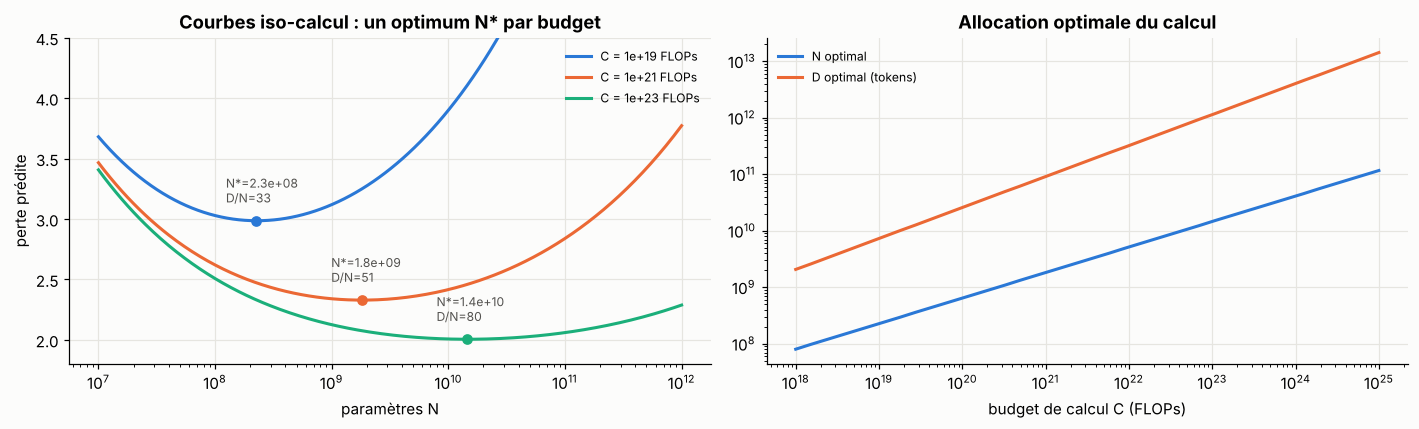

In [3]:
E_, A_, B_, alpha, beta = 1.69, 406.4, 410.7, 0.34, 0.28
L_fn = lambda N, D: E_ + A_ / N**alpha + B_ / D**beta

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for C, c in zip([1e19, 1e21, 1e23], PALETTE):
    N = np.logspace(7, 12, 300)
    D = C / (6 * N)
    loss = L_fn(N, D)
    axes[0].semilogx(N, loss, color=c, label=f"C = {C:.0e} FLOPs")
    i = np.argmin(loss)
    axes[0].plot(N[i], loss[i], "o", color=c)
    axes[0].annotate(f"N*={N[i]:.1e}\nD/N={D[i] / N[i]:.0f}", (N[i], loss[i]), xytext=(-20, 12), textcoords="offset points", fontsize=8, color="#52514e")
axes[0].set_ylim(1.8, 4.5); axes[0].set_xlabel("paramètres N"); axes[0].set_ylabel("perte prédite")
axes[0].set_title("Courbes iso-calcul : un optimum N* par budget"); axes[0].legend(fontsize=8)

Cs = np.logspace(18, 25, 40)
N_opt = []
for C in Cs:
    N = np.logspace(6, 13, 2000)
    N_opt.append(N[np.argmin(L_fn(N, C / (6 * N)))])
N_opt = np.array(N_opt)
axes[1].loglog(Cs, N_opt, label="N optimal")
axes[1].loglog(Cs, Cs / (6 * N_opt), label="D optimal (tokens)")
axes[1].set_xlabel("budget de calcul C (FLOPs)"); axes[1].set_title("Allocation optimale du calcul"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"slope of N_opt vs C: {np.polyfit(np.log(Cs), np.log(N_opt), 1)[0]:.2f}  "
      f"(theory for this formula: beta / (alpha + beta) = {beta / (alpha + beta):.2f}; 0.5 would mean N and D grow at the same rate)")

> ⚠️ **Lecture critique** : remarque que la formule tracée ici donne un ratio $D/N$ de 33 à 80 selon le budget, et non 20. La règle des « ~20 tokens par paramètre » vient des deux autres méthodes d'estimation du même article ; l'ajustement paramétrique (celui-ci) en diffère. Ces constantes sont propres à une famille de modèles, un tokenizer et un mélange de données ; les auteurs eux-mêmes ont été réanalysés (Besiroglu et al., 2024, trouvent des coefficients un peu différents). Et l'optimum « Chinchilla » minimise le coût d'**entraînement** : comme un modèle est ensuite utilisé des milliards de fois, on entraîne aujourd'hui volontairement des modèles plus **petits** sur **beaucoup plus** de tokens (LLaMA 3 8B : ~15 000 G tokens, soit ~1 900 tokens par paramètre), car ils coûtent moins cher à l'inférence. Pour des données **rares** (un domaine spécialisé, des séquences biologiques annotées), c'est $D$ qui limite : d'où l'intérêt de partir d'un modèle pré-entraîné.

## 4. L'écosystème Hugging Face en 10 minutes

| Librairie | Rôle |
|---|---|
| `transformers` | architectures + poids pré-entraînés (`AutoModel…`), tokenizers, `Trainer`, `generate` |
| `tokenizers` | tokenizers rapides (Rust) : BPE, WordPiece, Unigram (module 2) |
| `datasets` | chargement, transformation (`map`), cache de jeux de données |
| `accelerate` | même code sur CPU / 1 GPU / multi-GPU / précision mixte |
| `peft` | affinage efficace en paramètres (LoRA, module 8) |
| le **Hub** | des centaines de milliers de modèles et jeux de données, versionnés |

Le principe `Auto*` : un identifiant du Hub suffit à charger la bonne classe et les bons poids. Les têtes `AutoModelFor<Tâche>` ajoutent la couche de sortie adaptée au-dessus du Transformer.

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModel, AutoModelForMaskedLM, pipeline

device = "cuda" if torch.cuda.is_available() else "cpu"
name = "camembert-base"                       # RoBERTa-style French model (110 M parameters)
tok = AutoTokenizer.from_pretrained(name)
enc = tok(["Le film était vraiment excellent.", "Quelle déception !"], padding=True, return_tensors="pt")
print(enc.keys())                             # input_ids, attention_mask (module 1)
print(tok.convert_ids_to_tokens(enc["input_ids"][0]))

model = AutoModel.from_pretrained(name).to(device).eval()
with torch.no_grad():
    out = model(**{k: v.to(device) for k, v in enc.items()}, output_hidden_states=True, output_attentions=True)
print("last_hidden_state:", out.last_hidden_state.shape)              # (B, T, 768): contextual embeddings
print("hidden states:", len(out.hidden_states), "(embeddings + 12 layers)")
print("attentions:", len(out.attentions), out.attentions[0].shape)    # 12 x (B, 12 heads, T, T)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.0f} M parameters")

Le MLM en action : le modèle pré-entraîné sait déjà « remplir les trous ».

In [ ]:
fill = pipeline("fill-mask", model="camembert-base", device=0 if device == "cuda" else -1)
for s in ["Le chat <mask> sur le canapé.", "Paris est la <mask> de la France.", "La protéine se replie en une structure <mask>."]:
    print(s, "->", [(p["token_str"], round(p["score"], 3)) for p in fill(s, top_k=4)])

> 💡 Chaque modèle a son propre token de masque (`<mask>` pour CamemBERT/RoBERTa, `[MASK]` pour BERT) : utilise `tok.mask_token` plutôt que de l'écrire en dur.

## 5. Décoder : greedy, beam search, échantillonnage

Un modèle de langue donne $p(x_t\mid x_{<t})$ ; **décoder**, c'est choisir une séquence. Le module 4 a présenté l'échantillonnage (température, top-k, top-p). Reste la **recherche en faisceau** (*beam search*), qui cherche la séquence de **probabilité maximale** :

- **greedy** : à chaque pas, le token le plus probable. Myope : un premier choix localement optimal peut mener à une séquence globalement moins probable ;
- **beam search** (largeur $k$) : garder à chaque pas les $k$ préfixes de meilleure log-probabilité cumulée, étendre chacun de tous les tokens possibles, ne garder que les $k$ meilleurs. Normaliser par la longueur (sinon on favorise les séquences courtes).

Illustration sur un petit modèle de langue « jouet » où greedy se fait piéger :

In [4]:
# Toy LM: transition table p(next | current). The greedy first step ("le") leads to a poor continuation.
LM = {
    "<s>":   {"le": 0.5, "un": 0.4, "</s>": 0.1},
    "le":    {"chat": 0.3, "chien": 0.3, "rat": 0.2, "</s>": 0.2},
    "un":    {"oiseau": 0.9, "</s>": 0.1},
    "chat":  {"</s>": 1.0}, "chien": {"</s>": 1.0}, "rat": {"</s>": 1.0}, "oiseau": {"</s>": 1.0},
}

def greedy(lm, max_len=5):
    seq, logp = ["<s>"], 0.0
    while seq[-1] != "</s>" and len(seq) <= max_len:
        w, p = max(lm[seq[-1]].items(), key=lambda kv: kv[1])
        seq.append(w); logp += np.log(p)
    return seq, logp

def beam_search(lm, k=2, max_len=5):
    beams = [(["<s>"], 0.0)]
    for _ in range(max_len):
        candidates = []
        for seq, lp in beams:
            if seq[-1] == "</s>":
                candidates.append((seq, lp)); continue
            for w, p in lm[seq[-1]].items():
                candidates.append((seq + [w], lp + np.log(p)))
        beams = sorted(candidates, key=lambda c: c[1], reverse=True)[:k]
        if all(s[-1] == "</s>" for s, _ in beams):
            break
    return beams

g, lp = greedy(LM)
print(f"greedy     : {' '.join(g):30s} p = {np.exp(lp):.3f}")
for s, lp in beam_search(LM, k=2):
    print(f"beam (k=2) : {' '.join(s):30s} p = {np.exp(lp):.3f}")

greedy     : <s> le chat </s>               p = 0.150
beam (k=2) : <s> un oiseau </s>             p = 0.360
beam (k=2) : <s> le chat </s>               p = 0.150


Greedy choisit « le » (0.5 > 0.4) puis ne trouve que des suites à 0.3 : $p = 0.15$. Le beam garde « un » en réserve et trouve « un oiseau » : $p = 0.36$.

**Quand utiliser quoi** : beam search pour les tâches à **réponse correcte unique** (traduction, normalisation, annotation structurée) ; échantillonnage (top-p ≈ 0.9, température 0.7–1.0) pour la génération **ouverte** (le texte humain n'est pas le plus probable, module 4). Avec `transformers`, tout passe par `generate` :

In [ ]:
from transformers import AutoModelForCausalLM

gtok = AutoTokenizer.from_pretrained("gpt2")
gpt2 = AutoModelForCausalLM.from_pretrained("gpt2").to(device).eval()
prompt = gtok("The meaning of attention in neural networks is", return_tensors="pt").to(device)
settings = {
    "greedy": dict(do_sample=False),
    "beam (5)": dict(do_sample=False, num_beams=5, early_stopping=True),
    "beam + no_repeat_ngram": dict(do_sample=False, num_beams=5, no_repeat_ngram_size=3),
    "top-p 0.9, T=0.8": dict(do_sample=True, top_p=0.9, temperature=0.8),
    "top-k 40": dict(do_sample=True, top_k=40),
}
torch.manual_seed(0)
for label, kw in settings.items():
    out = gpt2.generate(**prompt, max_new_tokens=40, pad_token_id=gtok.eos_token_id, **kw)
    print(f"--- {label} ---\n{gtok.decode(out[0][prompt['input_ids'].shape[1]:], skip_special_tokens=True)}\n")

## 6. Affiner pour la classification de séquences

**Tâche** : sentiment sur les critiques de films Allociné (français, binaire). `AutoModelForSequenceClassification` ajoute au-dessus du Transformer une tête (dropout + linéaire) appliquée à la représentation du premier token (`[CLS]` / `<s>`). Tous les poids (tête **et** Transformer) sont entraînés.

### Les hyperparamètres de l'affinage (recette éprouvée de BERT)

| Hyperparamètre | Valeur typique | Pourquoi |
|---|---|---|
| learning rate | $1\cdot10^{-5}$ à $5\cdot10^{-5}$ | **petit** : on ajuste un modèle déjà bon, un grand pas détruit le pré-entraînement (*catastrophic forgetting*) |
| époques | 2 à 4 | le modèle sur-apprend vite |
| warmup | 6–10 % des pas | la tête est aléatoire au départ : gradients bruités |
| weight decay | 0.01 | AdamW |
| batch | 16–32 | |
| graine | **plusieurs** | l'affinage de BERT est notoirement instable sur les petits jeux : rapporte une moyenne sur 3–5 graines |

In [ ]:
from datasets import load_dataset
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding

ds = load_dataset("tblard/allocine")              # 160k / 20k / 20k movie reviews, columns: review, label
ds = ds.shuffle(seed=0)
small_train = ds["train"].select(range(8000))      # subsample to keep it fast; use everything on a GPU
small_val = ds["validation"].select(range(2000))

name = "camembert-base"
tok = AutoTokenizer.from_pretrained(name)

def tokenize(batch):
    return tok(batch["review"], truncation=True, max_length=256)     # no padding here: done per batch

train_tok = small_train.map(tokenize, batched=True, remove_columns=["review"])
val_tok = small_val.map(tokenize, batched=True, remove_columns=["review"])

clf = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2, id2label={0: "négatif", 1: "positif"},
                                                         label2id={"négatif": 0, "positif": 1})

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    tp = ((preds == 1) & (labels == 1)).sum(); fp = ((preds == 1) & (labels == 0)).sum(); fn = ((preds == 0) & (labels == 1)).sum()
    f1 = 2 * tp / max(1, 2 * tp + fp + fn)
    return {"accuracy": (preds == labels).mean(), "f1": f1}

args = TrainingArguments(
    output_dir="camembert-allocine", num_train_epochs=2, learning_rate=2e-5, weight_decay=0.01,
    per_device_train_batch_size=16, per_device_eval_batch_size=64, warmup_ratio=0.1, lr_scheduler_type="linear",
    eval_strategy="epoch", save_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="f1",
    logging_steps=50, fp16=torch.cuda.is_available(), seed=0, report_to="none",
)   # note: older transformers versions call it `evaluation_strategy`
trainer = Trainer(model=clf, args=args, train_dataset=train_tok, eval_dataset=val_tok,
                  data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics)
trainer.train()
print(trainer.evaluate())

In [ ]:
clf.eval()
reviews = ["Un chef-d'œuvre, je suis sorti bouleversé.", "Pas mauvais du tout, contre toute attente.",
           "Le film n'est pas excellent, mais les acteurs sont bons.", "Deux heures de ma vie que je ne récupérerai jamais."]
with torch.no_grad():
    batch = tok(reviews, padding=True, return_tensors="pt").to(clf.device)
    probs = clf(**batch).logits.softmax(-1)[:, 1].cpu()
for r_, p in zip(reviews, probs):
    print(f"p(positif) = {p:.2f} | {r_}")

Compare avec le module 2 : les négations, le contraste et les expressions jamais vues (« chef-d'œuvre », « je ne récupérerai jamais ») sont maintenant gérés, grâce au **contexte** et à la connaissance de la langue acquise au pré-entraînement.

**Ce que fait `Trainer`, en clair** (c'est la boucle du module 1) :

In [ ]:
from torch.utils.data import DataLoader
from transformers import get_linear_schedule_with_warmup

loader = DataLoader(train_tok, batch_size=16, shuffle=True, collate_fn=DataCollatorWithPadding(tok))   # the collator pads and renames "label" -> "labels"
model_manual = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2).to(device)
opt = torch.optim.AdamW(model_manual.parameters(), lr=2e-5, weight_decay=0.01)
total = len(loader) * 2
sched = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
model_manual.train()
for epoch in range(2):
    for step, batch in enumerate(loader):
        batch = {k: v.to(device) for k, v in batch.items()}       # input_ids, attention_mask, labels
        out = model_manual(**batch)                               # the loss is computed inside when labels are given
        out.loss.backward()
        torch.nn.utils.clip_grad_norm_(model_manual.parameters(), 1.0)
        opt.step(); sched.step(); opt.zero_grad()
        if step % 100 == 0:
            print(f"epoch {epoch} step {step} loss {out.loss.item():.4f}")

## 7. Affiner pour l'étiquetage de tokens

### 💡 La tâche

Une étiquette **par mot** : reconnaissance d'entités nommées (personne, lieu, date…), étiquetage morpho-syntaxique, ou **délimitation de segments** dans une séquence (régions fonctionnelles d'une protéine, module 9). Le schéma standard est **BIO** :
- `B-X` : début d'une entité de type X ;
- `I-X` : intérieur (suite) d'une entité X ;
- `O` : hors entité.

```
Marie   Curie  est  née  à  Varsovie  le  7     novembre  1867  .
B-PER   I-PER  O    O    O  B-LOC     O   B-DATE I-DATE   I-DATE O
```

### 📐 Le problème de l'alignement mots / sous-mots

Les étiquettes sont données **par mot**, mais le modèle voit des **sous-mots** (module 2) : « Varsovie » → `▁Var`, `sov`, `ie`. Il faut aligner. Convention standard : l'étiquette du mot va sur son **premier** sous-mot ; les autres sous-mots et les tokens spéciaux reçoivent `-100` (ignorés par la perte, module 4). Les tokenizers rapides fournissent `word_ids()`, l'indice du mot d'origine de chaque sous-mot.

In [5]:
# Pure-Python illustration of the alignment (the word_ids below are what a fast tokenizer returns)
words = ["Marie", "Curie", "est", "née", "à", "Varsovie", "."]
tags = ["B-PER", "I-PER", "O", "O", "O", "B-LOC", "O"]
subwords = ["<s>", "▁Marie", "▁Cur", "ie", "▁est", "▁née", "▁à", "▁Var", "sov", "ie", "▁.", "</s>"]
word_ids = [None, 0, 1, 1, 2, 3, 4, 5, 5, 5, 6, None]
label_list = ["O", "B-PER", "I-PER", "B-LOC", "I-LOC", "B-DATE", "I-DATE"]
label2id = {l: i for i, l in enumerate(label_list)}

def align_labels(word_ids, word_tags):
    aligned, prev = [], None
    for w in word_ids:
        if w is None:
            aligned.append(-100)                      # special tokens
        elif w != prev:
            aligned.append(label2id[word_tags[w]])    # first sub-word of a word: real label
        else:
            aligned.append(-100)                      # continuation sub-words: ignored
        prev = w
    return aligned

for sw, wi, lab in zip(subwords, word_ids, align_labels(word_ids, tags)):
    print(f"{sw:10s} word_id={str(wi):4s} label={lab:5d}  {label_list[lab] if lab >= 0 else '(ignored)'}")

<s>        word_id=None label= -100  (ignored)
▁Marie     word_id=0    label=    1  B-PER
▁Cur       word_id=1    label=    2  I-PER
ie         word_id=1    label= -100  (ignored)
▁est       word_id=2    label=    0  O
▁née       word_id=3    label=    0  O
▁à         word_id=4    label=    0  O
▁Var       word_id=5    label=    3  B-LOC
sov        word_id=5    label= -100  (ignored)
ie         word_id=5    label= -100  (ignored)
▁.         word_id=6    label=    0  O
</s>       word_id=None label= -100  (ignored)


### 📐 L'évaluation au niveau des entités

Une précision « par token » est trompeuse : la majorité des tokens sont `O`. On évalue au niveau des **entités** (comme la librairie `seqeval`) : une entité prédite n'est correcte que si son **type** et ses **deux bornes** sont exactement justes.

In [6]:
def bio_to_spans(tags):
    """['B-PER','I-PER','O','B-LOC'] -> {('PER',0,2), ('LOC',3,4)} (end exclusive). Lenient on stray I- tags."""
    spans, start, typ = set(), None, None
    for i, t in enumerate(list(tags) + ["O"]):
        boundary = t == "O" or t.startswith("B-") or (t.startswith("I-") and t[2:] != typ)
        if boundary and start is not None:
            spans.add((typ, start, i)); start, typ = None, None
        if t.startswith("B-") or (t.startswith("I-") and start is None):
            start, typ = i, t[2:]
    return spans

def entity_prf(true_seqs, pred_seqs):
    tp = fp = fn = 0
    for t, p in zip(true_seqs, pred_seqs):
        T_, P_ = bio_to_spans(t), bio_to_spans(p)
        tp += len(T_ & P_); fp += len(P_ - T_); fn += len(T_ - P_)
    prec = tp / max(1, tp + fp); rec = tp / max(1, tp + fn)
    return prec, rec, 2 * prec * rec / max(1e-12, prec + rec)

gold = ["B-PER", "I-PER", "O", "O", "O", "B-LOC", "O", "B-DATE", "I-DATE", "I-DATE"]
preds = {
    "parfait": gold,
    "frontière droite trop courte": ["B-PER", "I-PER", "O", "O", "O", "B-LOC", "O", "B-DATE", "I-DATE", "O"],
    "mauvais type": ["B-PER", "I-PER", "O", "O", "O", "B-PER", "O", "B-DATE", "I-DATE", "I-DATE"],
    "tout O": ["O"] * 10,
}
for name_, p in preds.items():
    token_acc = np.mean([a == b for a, b in zip(gold, p)])
    pr, rc, f1 = entity_prf([gold], [p])
    print(f"{name_:30s} token acc {token_acc:.2f} | entity P {pr:.2f} R {rc:.2f} F1 {f1:.2f}")

parfait                        token acc 1.00 | entity P 1.00 R 1.00 F1 1.00
frontière droite trop courte   token acc 0.90 | entity P 0.67 R 0.67 F1 0.67
mauvais type                   token acc 0.90 | entity P 0.67 R 0.67 F1 0.67
tout O                         token acc 0.40 | entity P 0.00 R 0.00 F1 0.00


Note le cas « frontière trop courte » : 90 % des tokens sont justes, mais l'entité DATE est **fausse** (et compte à la fois comme un faux positif et un faux négatif). Pour la délimitation de régions, on rapporte souvent en plus une **tolérance aux frontières** (± 1 ou 2 positions) ou un recouvrement (IoU), car une erreur d'une position n'a pas la même gravité qu'une région manquée.

### L'entraînement

Pour rester autonome, on génère un petit jeu d'entraînement synthétique ; remplace-le par un vrai corpus (par exemple `load_dataset("conll2003")` en anglais, en vérifiant l'identifiant actuel sur le Hub) pour un usage réel.

In [ ]:
import random
from datasets import Dataset
from transformers import AutoModelForTokenClassification, DataCollatorForTokenClassification

PER = [["Marie", "Curie"], ["Victor", "Hugo"], ["Ada", "Lovelace"], ["Louis", "Pasteur"], ["Simone", "Veil"], ["Alan", "Turing"]]
LOC = [["Paris"], ["Varsovie"], ["Lyon"], ["New", "York"], ["Saint-Étienne"], ["Londres"]]
MONTHS = ["janvier", "mars", "juin", "septembre", "novembre"]

def synth_example(r):
    p, l = r.choice(PER), r.choice(LOC)
    date = [str(r.randint(1, 28)), r.choice(MONTHS), str(r.randint(1800, 2020))]
    pattern = r.choice([
        (p, ["est", "né(e)", "à"], l, ["le"], date, ["."]),
        (["Le"], date, [","], p, ["a", "visité"], l, ["."]),
        (["À"], l, [","], p, ["a", "travaillé", "jusqu'au"], date, ["."]),
    ])
    words, tags = [], []
    for chunk in pattern:
        typ = "PER" if chunk is p else "LOC" if chunk is l else "DATE" if chunk is date else None
        for i, w in enumerate(chunk):
            words.append(w); tags.append("O" if typ is None else ("B-" if i == 0 else "I-") + typ)
    return {"words": words, "tags": [label2id[t] for t in tags]}

r_ = random.Random(0)
ner_ds = Dataset.from_list([synth_example(r_) for _ in range(2000)]).train_test_split(test_size=0.2, seed=0)

name = "camembert-base"
tok = AutoTokenizer.from_pretrained(name)

def tokenize_and_align(batch):
    enc = tok(batch["words"], is_split_into_words=True, truncation=True)
    enc["labels"] = [align_labels(enc.word_ids(i), [label_list[t] for t in tags]) for i, tags in enumerate(batch["tags"])]
    return enc

ner_tok = ner_ds.map(tokenize_and_align, batched=True, remove_columns=["words", "tags"])
ner_model = AutoModelForTokenClassification.from_pretrained(
    name, num_labels=len(label_list), id2label=dict(enumerate(label_list)), label2id=label2id)

def ner_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    true_seqs, pred_seqs = [], []
    for p_row, l_row in zip(preds, labels):
        keep = l_row != -100                                    # evaluate on first sub-words only
        true_seqs.append([label_list[i] for i in l_row[keep]])
        pred_seqs.append([label_list[i] for i in p_row[keep]])
    pr, rc, f1 = entity_prf(true_seqs, pred_seqs)
    return {"entity_precision": pr, "entity_recall": rc, "entity_f1": f1}

ner_args = TrainingArguments(output_dir="camembert-ner", num_train_epochs=3, learning_rate=3e-5,
                             per_device_train_batch_size=16, warmup_ratio=0.1, weight_decay=0.01,
                             eval_strategy="epoch", save_strategy="no", report_to="none", seed=0)
ner_trainer = Trainer(model=ner_model, args=ner_args, train_dataset=ner_tok["train"], eval_dataset=ner_tok["test"],
                      data_collator=DataCollatorForTokenClassification(tok), compute_metrics=ner_metrics)
ner_trainer.train()

In [ ]:
@torch.no_grad()
def tag_sentence(words):
    ner_model.eval()
    enc = tok(words, is_split_into_words=True, return_tensors="pt").to(ner_model.device)
    pred = ner_model(**enc).logits.argmax(-1)[0].tolist()
    out, prev = [], None
    for wi, p in zip(enc.word_ids(), pred):
        if wi is not None and wi != prev:
            out.append((words[wi], label_list[p]))
        prev = wi
    return out

print(tag_sentence("Grace Hopper a visité Marseille le 12 mai 1970 .".split()))

> 🔍 **Test de généralisation** : « Grace Hopper » et « Marseille » n'apparaissent pas dans les données synthétiques. Si le modèle les étiquette correctement, c'est grâce au **pré-entraînement** (il sait ce qu'est un prénom, une ville), pas aux 1 600 phrases-gabarits. Un modèle entraîné de zéro sur ces données échouerait.

## 8. Extraire des embeddings de phrases

Pour la recherche sémantique, le regroupement ou la visualisation, on veut **un vecteur par phrase**. La méthode la plus simple : la **moyenne masquée** des derniers états cachés (module 1). Le vecteur `[CLS]` d'un modèle MLM non affiné est généralement **moins bon** que la moyenne.

In [ ]:
emb_model = AutoModel.from_pretrained("camembert-base").to(device).eval()

@torch.no_grad()
def sentence_embeddings(sentences):
    enc = tok(sentences, padding=True, truncation=True, return_tensors="pt").to(device)
    h = emb_model(**enc).last_hidden_state                          # (B, T, d)
    m = enc["attention_mask"].unsqueeze(-1).float()
    e = (h * m).sum(1) / m.sum(1)                                   # masked mean pooling
    return torch.nn.functional.normalize(e, dim=-1)

S = ["Le chat dort sur le canapé.", "Un félin fait la sieste sur le sofa.", "La bourse a chuté ce matin.", "Les marchés financiers sont en baisse."]
E = sentence_embeddings(S)
print((E @ E.T).cpu().numpy().round(2))

> ⚠️ Les embeddings d'un modèle MLM brut sont **anisotropes** (tous les vecteurs occupent un cône étroit, les cosinus sont tous élevés). Pour de la recherche sémantique sérieuse, on utilise des modèles **entraînés pour ça** par apprentissage contrastif (`sentence-transformers`, par exemple `paraphrase-multilingual-MiniLM-L12-v2`), où paraphrases et non-paraphrases sont explicitement rapprochées et éloignées.

## 9. Des modèles de base aux assistants

Un modèle CLM pré-entraîné (« modèle de base ») **complète** du texte ; il ne suit pas d'instructions. Les assistants conversationnels ajoutent deux étapes :

1. **Instruction tuning / SFT** (*supervised fine-tuning*) : affinage CLM sur des paires (instruction, bonne réponse) rédigées ou validées par des humains. La perte n'est calculée que sur les tokens de la **réponse** (les tokens de l'instruction reçoivent `-100`, encore lui).
2. **Alignement sur les préférences** : on collecte des comparaisons « réponse A préférée à réponse B », puis :
   - **RLHF** : entraîner un modèle de récompense $r_\phi$ sur ces préférences, puis optimiser le modèle de langue par apprentissage par renforcement (PPO) pour maximiser $r_\phi$, avec une pénalité KL pour ne pas trop s'éloigner du modèle SFT ;
   - **DPO** (Rafailov et al., 2023) : obtenir le même optimum **sans** modèle de récompense ni RL, avec une perte de classification directe :
$$
\mathcal L_{\text{DPO}} = -\log\sigma\!\left(\beta\log\frac{\pi_\theta(y_w\mid x)}{\pi_{\text{ref}}(y_w\mid x)} - \beta\log\frac{\pi_\theta(y_l\mid x)}{\pi_{\text{ref}}(y_l\mid x)}\right)
$$
   où $y_w$ est la réponse préférée et $y_l$ la rejetée. On augmente la probabilité relative de la bonne réponse par rapport à la mauvaise, en restant ancré au modèle de référence.

Ces étapes dépassent le cadre de ce cours ; la librairie `trl` de Hugging Face les implémente (`SFTTrainer`, `DPOTrainer`).

## 10. Récapitulatif

| Notion | À retenir |
|---|---|
| Transfert | pré-entraîner (auto-supervisé, données massives) puis affiner (supervisé, peu de données) |
| CLM | $-\sum_t\log p(x_t\mid x_{<t})$ ; 100 % des tokens ; génère |
| MLM | 15 % des tokens, règle 80/10/10, perte sur les positions sélectionnées ; bidirectionnel |
| Lois d'échelle | $L = E + A/N^\alpha + B/D^\beta$ ; $C\approx 6ND$ ; ~20 tokens/paramètre (optimum d'entraînement) |
| Hugging Face | `AutoTokenizer`, `AutoModelFor…`, `datasets.map`, `Trainer`, `generate` |
| Décodage | beam search pour une réponse unique ; top-p pour la génération ouverte |
| Affinage | lr 1e-5–5e-5, 2–4 époques, warmup, plusieurs graines |
| Étiquetage de tokens | BIO ; étiquette sur le 1er sous-mot, `-100` ailleurs ; F1 **par entité** |
| Embeddings de phrases | moyenne masquée ; préférer des modèles contrastifs |
| Assistants | SFT puis RLHF / DPO |

### 🏋️ Exercices

1. **Masquage.** Modifie `mlm_mask` pour masquer des **mots entiers** (tous les sous-mots d'un mot ensemble, *whole word masking*) puis des **segments** contigus (SpanBERT). Pourquoi rendent-ils la tâche plus difficile, et plus utile ?
2. **Courbe d'apprentissage.** Affine CamemBERT sur 100, 500, 2 000 et 8 000 critiques Allociné, et compare avec le TF-IDF + régression logistique du module 2 entraîné sur les mêmes sous-ensembles. À partir de combien d'exemples le pré-entraînement cesse-t-il d'être un avantage décisif ?
3. **Instabilité.** Relance l'affinage de la section 6 avec 5 graines différentes sur 500 exemples. Rapporte moyenne et écart-type. Que conclure d'une comparaison entre deux modèles faite sur une seule graine ?
4. **Étiquettes des sous-mots.** Au lieu de `-100`, donne aux sous-mots de continuation l'étiquette `I-X` correspondante. Compare le F1 par entité. Quels sont les avantages et inconvénients de chaque convention ?
5. **Gel des couches.** Affine en gelant le Transformer (seule la tête est entraînée), puis en gelant seulement les 6 premières couches. Compare précision et temps d'entraînement. Relie au compromis « geler ou affiner » du module 3.

<details><summary>Indications</summary>

1. Masquer un seul sous-mot d'un mot est souvent trivial (« Var##[MASK]##ie »). Masquer le mot entier force à utiliser le contexte phrastique.
2. On observe classiquement un gros avantage du pré-entraînement en régime de très peu de données, qui se réduit (sans disparaître) quand les données augmentent.
3. Les écarts-types sur petits jeux atteignent souvent plusieurs points d'accuracy : une seule graine peut inverser le classement de deux méthodes.
5. `for p in clf.base_model.parameters(): p.requires_grad = False`, ou seulement `clf.base_model.encoder.layer[:6]` et les embeddings.
</details>

**➡️ Module suivant : adaptation efficace** (DAPT/TAPT, LoRA et PEFT, apprentissage multi-tâche et pondération des pertes par incertitude, évaluation rigoureuse et calibration).